## Semiconductor Lab B7 - Task 3 & 4

### Task 3 
Measure the spectrum of spontaneous emission of the laser diode by operating it at a very
low current density as LED. Determine the effective carrier temperature from the gradient
in the high-energy range by using the line shape model for spontaneous emission.
### Task 4
 Measure the spectrum at a higher operating current below the threshold and again
determine the effective temperature. Compare the result with (3) and find conclusions.

In [65]:
%matplotlib inline

from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import pandas as pd
from scipy import constants
from scipy.optimize import curve_fit

from b7.python.config import DATA_DIR, DOUBLE_COLUMN, PLOTS_DIR
from b7.python.helper import read_spectrum

In [66]:
data_dir: Path = DATA_DIR / "task_3_4_5"
export_dir: Path = PLOTS_DIR

### Import Data

- `0.1mA.txt` is the LED regime of task 3
- `9.9mA.txt` the higher sub-threshold current of task 4.

In [67]:
df_led: pd.DataFrame = read_spectrum(data_dir / "0.1mA.txt")
df_sub: pd.DataFrame = read_spectrum(data_dir / "9.9mA.txt")

### Enrich Data

#### Enrich DataFrame

In [68]:
LAMBDA_REF_NM: float = 780.0  # only sets the arbitrary scale of the density below

# Lock-in signal converted from a per-wavelength to a per-energy spectral density. The scan
# steps the detection monochromator in constant intervals of wavelength, so the recorded
# signal is proportional to I_lambda. The line shape model is written for I_E, and
# I_E = I_lambda |dlambda/dE| with |dlambda/dE| = lambda^2 / (h c).
df_led["S_E"] = df_led["signal"] * (df_led["lambda_nm"] / LAMBDA_REF_NM) ** 2
df_sub["S_E"] = df_sub["signal"] * (df_sub["lambda_nm"] / LAMBDA_REF_NM) ** 2

#### Fit Data

In [ ]:
WINDOW_LED: tuple[float, float] = (732.0, 782.0)
WINDOW_SUB: tuple[float, float] = (726.0, 768.0)

KB_EV: float = constants.k / constants.e  # Boltzmann constant in eV/K

In [70]:
def spontaneous_emission(E: npt.NDArray[np.float64], E_g: float, T_c: float, A: float) -> npt.NDArray[np.float64]:
    """Spontaneous emission line shape, with E and E_g in eV and T_c in K.

    Written in terms of E - E_g rather than E so that the amplitude does not have to absorb a
    factor exp(E_g / k T_c) that is many orders of magnitude large, which would leave the fit
    badly scaled. Clipping the argument keeps the square root real for E < E_g.
    """
    x: npt.NDArray[np.float64] = np.clip(E - E_g, 0.0, None)
    return A * np.sqrt(x) * np.exp(-x / (KB_EV * T_c))


def log_spontaneous_emission(
    E: npt.NDArray[np.float64], E_g: float, T_c: float, ln_A: float
) -> npt.NDArray[np.float64]:
    """Natural logarithm of `spontaneous_emission`, which is what is actually fitted."""
    x: npt.NDArray[np.float64] = np.clip(E - E_g, 1e-12, None)
    return ln_A + 0.5 * np.log(x) - x / (KB_EV * T_c)

In [75]:
mask_led: pd.Series = df_led["lambda_nm"].between(*WINDOW_LED) & (df_led["S_E"] > 0)
E_led: npt.NDArray[np.float64] = df_led.loc[mask_led, "E_eV"].to_numpy()
ln_S_led: npt.NDArray[np.float64] = np.log(df_led.loc[mask_led, "S_E"].to_numpy())

# E_g has to stay below the window, otherwise the logarithm of E - E_g is undefined on the
# first point.
(E_g_led, T_c_led, ln_A_led), cov_led = curve_fit(
    log_spontaneous_emission,
    E_led,
    ln_S_led,
    p0=[E_led.min() - 0.05, 300.0, 0.0],
    bounds=([1.0, 50.0, -60.0], [E_led.min() - 1e-3, 3000.0, 60.0]),
)
E_g_led_err, T_c_led_err, _ = np.sqrt(np.diag(cov_led))

fit_led = {
    "n_points": int(mask_led.sum()),
    "E_g": E_g_led,
    "E_g_err": E_g_led_err,
    "T_c": T_c_led,
    "T_c_err": T_c_led_err,
    "kT_meV": KB_EV * T_c_led * 1e3,
}
pprint(fit_led)

{'E_g': np.float64(1.5602885007594662),
 'E_g_err': np.float64(0.008384879714921538),
 'T_c': np.float64(285.4256061557573),
 'T_c_err': np.float64(7.735044237822247),
 'kT_meV': np.float64(24.59607569793957),
 'n_points': 26}


In [72]:
mask_sub: pd.Series = df_sub["lambda_nm"].between(*WINDOW_SUB) & (df_sub["S_E"] > 0)
E_sub: npt.NDArray[np.float64] = df_sub.loc[mask_sub, "E_eV"].to_numpy()
ln_S_sub: npt.NDArray[np.float64] = np.log(df_sub.loc[mask_sub, "S_E"].to_numpy())

# E_g is held fixed at the LED value: at 9.9 mA the band edge sits under the amplified part
# of the line, and running it free lets it wander into a flat direction of the fit.
(T_c_sub, ln_A_sub), cov_sub = curve_fit(
    lambda E, T_c, ln_A: log_spontaneous_emission(E, E_g_led, T_c, ln_A),
    E_sub,
    ln_S_sub,
    p0=[300.0, 0.0],
    bounds=([50.0, -60.0], [3000.0, 60.0]),
)
T_c_sub_err, _ = np.sqrt(np.diag(cov_sub))

fit_sub = {
    "n_points": int(mask_sub.sum()),
    "E_g": E_g_led,
    "T_c": T_c_sub,
    "T_c_err": T_c_sub_err,
    "kT_meV": KB_EV * T_c_sub * 1e3,
}
pprint(fit_sub)

{'E_g': np.float64(1.5602885007594662),
 'T_c': np.float64(233.66117763877722),
 'T_c_err': np.float64(1.758484505846708),
 'kT_meV': np.float64(20.135362381386482),
 'n_points': 22}


### Plot Data

#### Preparation

In [84]:
# Smooth line shape curve over each fitted window, padded a bit on either side
pad = 0.02
E_led_curve = np.linspace(E_led.min() - pad, E_led.max() + pad, 400)
S_led_curve = np.exp(log_spontaneous_emission(E_led_curve, E_g_led, T_c_led, ln_A_led))

E_sub_curve = np.linspace(E_sub.min() - pad, E_sub.max() + pad, 400)
S_sub_curve = np.exp(log_spontaneous_emission(E_sub_curve, E_g_led, T_c_sub, ln_A_sub))

# Square root divided out, so the carrier temperature is simply the slope of a straight line
x_led = E_led - E_g_led
ln_S_led_flat = ln_S_led - 0.5 * np.log(x_led)
ln_S_led_flat_fit = ln_A_led - x_led / (KB_EV * T_c_led)

x_sub = E_sub - E_g_led
ln_S_sub_flat = ln_S_sub - 0.5 * np.log(x_sub)
ln_S_sub_flat_fit = ln_A_sub - x_sub / (KB_EV * T_c_sub)

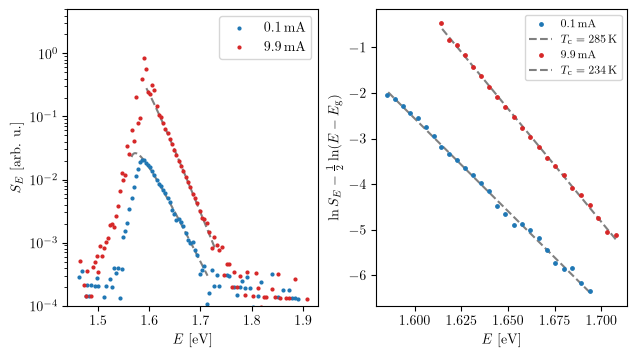

In [ ]:
with plt.rc_context(DOUBLE_COLUMN):
    fig, (ax1, ax2) = plt.subplots(ncols=2, layout="constrained")

    ax1.scatter(df_led["E_eV"], df_led["S_E"], s=4, color="tab:blue", label=r"\qty{0.1}{\milli\ampere}")
    ax1.scatter(df_sub["E_eV"], df_sub["S_E"], s=4, color="tab:red", label=r"\qty{9.9}{\milli\ampere}")

    ax1.plot(E_sub_curve, S_sub_curve, color="grey", linestyle="--", zorder=-1)
    ax1.plot(E_led_curve, S_led_curve, color="grey", linestyle="--", zorder=-1)

    ax1.set_yscale("log")
    ax1.set_ylim(1e-4, 5)
    ax1.legend(loc="upper right")

    ax1.set_xlabel(r"$E$ [\unit{\electronvolt}]")
    ax1.set_ylabel(r"$S_E$ [arb. u.]")

    ax2.scatter(E_led, ln_S_led_flat, s=6, color="tab:blue", label=r"\qty{0.1}{\milli\ampere}")
    ax2.scatter(E_sub, ln_S_sub_flat, s=6, color="tab:red", label=r"\qty{9.9}{\milli\ampere}")
    ax2.plot(
        E_led,
        ln_S_led_flat_fit,
        color="grey",
        linestyle="--",
        zorder=-1,
        label=rf"$T_\mathrm{{c}} = \qty{{{T_c_led:.0f}}}{{\kelvin}}$",
    )
    ax2.plot(
        E_sub,
        ln_S_sub_flat_fit,
        color="grey",
        linestyle="--",
        zorder=-1,
        label=rf"$T_\mathrm{{c}} = \qty{{{T_c_sub:.0f}}}{{\kelvin}}$",
    )
    ax2.set_xlabel(r"$E$ [\unit{\electronvolt}]")
    ax2.set_ylabel(r"$\ln S_E - \frac{1}{2} \ln (E - E_\mathrm{g})$")
    ax2.legend(loc="upper right", fontsize=8)

    fig.savefig(export_dir / "spontaneous_emission.pdf")
    plt.show()

### Result

|        | $I_\mathrm{D}$ | FWHM   | $E_\mathrm{g}$ | $T_\mathrm{c}$    |
|--------|----------------|--------|----------------|-------------------|
| Task 3 | 0.1 mA         | 20 nm  | 1.56 eV        | $(285 \pm 12)$ K  |
| Task 4 | 9.9 mA         | 4.8 nm | fixed          | $(234 \pm 4)$ K   |

At 0.1 mA the diode really is an LED: the line is 20 nm wide, the model describes the whole
flank to within a few percent, and the carrier temperature comes out at room temperature within
the uncertainty. The band edge of 1.56 eV (795 nm) is what an AlGaAs active layer emitting at
780 nm should have.

At 9.9 mA the fit is even cleaner but the number it returns is *lower*, and a carrier
temperature below the lattice temperature is not physical. The line width is the reason: it
collapses from 20 nm to 4.8 nm, so the diode is already amplifying its own spontaneous emission
well below threshold. The single-pass gain peaks near the band edge and turns into absorption
above the quasi-Fermi-level separation, so it multiplies the spectrum by a factor that falls
with photon energy and steepens the flank. What the fit measures at this current is the gain
spectrum on top of the carrier distribution, not the carrier distribution alone.

One systematic applies to both: the wavelength dependent efficiency of grating and detector was
not calibrated out, and over 730 nm to 790 nm it tilts the flank in the same direction for both
currents.